# Milestone 4: Sentiment Analysis from Classic NLP to LLMs
Dataset: Financial PhraseBank (`all-data.csv`).

## 0 Setup

In [54]:
import os
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import anthropic
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud, STOPWORDS

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")

In [55]:
from dotenv import load_dotenv
load_dotenv()

True

In [56]:
print(os.getenv("ANTHROPIC_API_KEY") is not None)

True


In [57]:
os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)

## 1 Import Data

In [58]:
df = pd.read_csv("all-data.csv", header=None, names=["sentiment", "text"], encoding="latin-1")
df.head()

,sentiment,text
0,neutral,"According to Gran , the company has no plans to move all productio..."
1,neutral,Technopolis plans to develop in stages an area of no less than 100...
2,negative,The international electronic industry company Elcoteq has laid off...
3,positive,With the new production plant the company would increase its capac...
4,positive,According to the company 's updated strategy for the years 2009-20...


In [59]:
df.shape

(4846, 2)

In [60]:
df = df.drop_duplicates(subset="text").reset_index(drop=True)
df.shape

(4838, 2)

In [61]:
LABELS = ["negative", "neutral", "positive"]

## 2 EDA

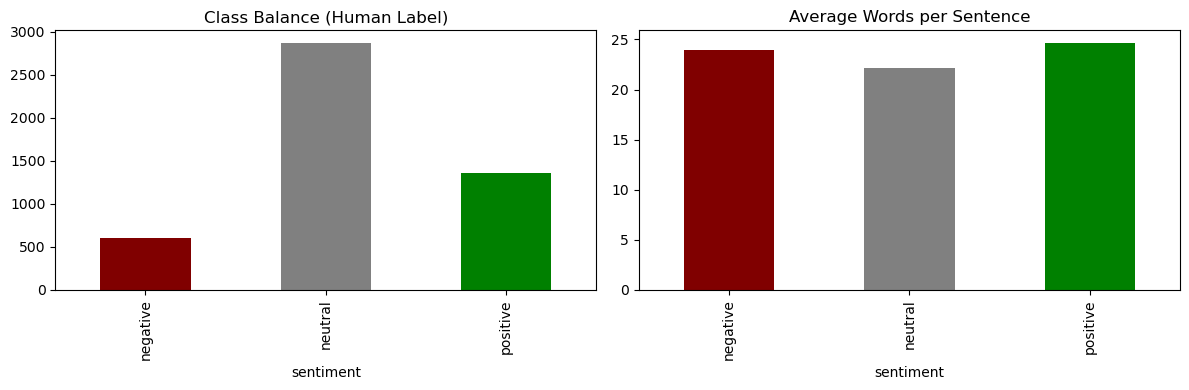

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))

df['sentiment'].value_counts().reindex(LABELS).plot.bar(
    ax=axes[0], color=['maroon', 'gray', 'green'])
axes[0].set_title("Class Balance (Human Label)")

df['n_words'] = df['text'].str.split().str.len()
df.groupby('sentiment')['n_words'].mean().reindex(LABELS).plot.bar(
    ax=axes[1], color=['maroon', 'gray', 'green'])
axes[1].set_title("Average Words per Sentence")
plt.tight_layout()
plt.savefig("results/eda.png")
plt.show()

In [63]:
print(df['sentiment'].value_counts(normalize=True).round(3))
print("\nAverage length:", round(df['n_words'].mean(), 1), "words")

sentiment
neutral     0.594
positive    0.282
negative    0.125
Name: proportion, dtype: float64

Average length: 23.1 words


### 10 Random Examples per Class

In [64]:
pd.set_option("display.max_colwidth", 150)

for label in LABELS:
    print(f"==={label}===")
    for t in df[df['sentiment'] == label]['text'].sample(10, random_state=42):
        print("-", t)
    print()

===negative===
- The company decided at the end of 2008 to temporarily shut down its ammonia plant in Billingham and extend the maintenance period at its Ince facility .
- down to EUR5 .9 m H1 '09 3 August 2009 - Finnish media group Ilkka-Yhtyma Oyj ( HEL : ILK2S ) said today its net profit fell 45 % on the year to EUR5 .9 m in the first half of 2009 .
- The steelmaker said that the drop in profit was explained by the continuing economic uncertainty , mixed with the current drought in bank lending , resulting in a decline in demand for its products as customers find it increasingly difficult to fund operations .
- Finland-based Stockmann Group has closed seven franchising sports stores Nike in Russia .
- Operating loss before non-recurring items was EUR 0.9 mn , compared to a profit of EUR 11.5 mn in 2008 .
- A high court in Finland has fined seven local asphalt companies more than   lion ( $ 117 million ) for operating a cartel .
- ( ADPnews ) - Feb 3 , 2010 - Finland-based steel make

### WordCloud

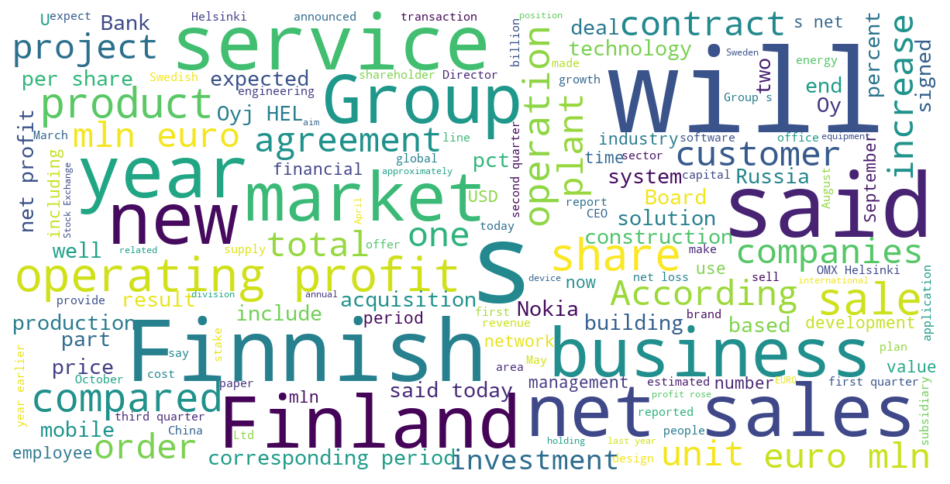

In [65]:
sentences = df['text'].str.cat(sep=" ")

all_stopwords = STOPWORDS | {"EUR", "mn", "m", "million", "company"}

wordcloud = WordCloud(
    background_color = 'white',
    stopwords = all_stopwords,
    max_words = 200,
    max_font_size = 50,
    scale = 3,
    random_state = 1
).generate(sentences)

plt.figure(figsize=(12,12))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

## 3 Train/Test Split

In [66]:
train, test = train_test_split(df, test_size=0.2, random_state=42,
                               stratify=df["sentiment"])

test, _ = train_test_split(test, train_size=300, random_state=42,
                           stratify=test["sentiment"])

y_train = train['sentiment'].to_numpy()
y_test = test['sentiment'].to_numpy()

print(len(train), 'train data; ', len(test), 'test data')

train.to_csv("data/train.csv", index=False)
test.to_csv("data/test_subset_300.csv", index=False)

3870 train data;  300 test data


In [67]:
test['sentiment'].value_counts()

sentiment
neutral     178
positive     84
negative     38
Name: count, dtype: int64

### Hard Cases (30 sentences)

In [68]:
hard_cases = [
    ("The company did not report any losses this quarter.", "positive"),
    ("Sales were not as strong as analysts had hoped.", "negative"),
    ("Management does not expect the restructuring to hurt profitability.", "positive"),
    ("The merger is no longer expected to create value for shareholders.", "negative"),
    ("The operating loss narrowed to EUR 2.1 mn from EUR 9.4 mn a year earlier.", "positive"),
    ("Net debt decreased significantly during the period.", "positive"),
    ("Costs increased sharply, eating into the operating margin.", "negative"),
    ("Unemployment claims fell to their lowest level in a decade.", "positive"),
    ("The company cut its full-year profit guidance.", "negative"),
    ("Impairment charges rose to EUR 45 mn.", "negative"),
    ("Despite weak demand in Europe, total revenue grew by 12 %.", "positive"),
    ("Although sales increased, the company swung to a net loss.", "negative"),
    ("Revenue beat expectations, but the outlook for next year was lowered.", "negative"),
    ("The firm closed two plants, yet operating profit still doubled.", "positive"),
    ("Operating profit was EUR 5.0 mn compared to EUR 8.2 mn in 2008.", "negative"),
    ("Earnings per share were EUR 0.45 versus EUR 0.30 a year ago.", "positive"),
    ("Order intake totaled EUR 120 mn, compared with EUR 95 mn in the previous quarter.", "positive"),
    ("Net sales amounted to EUR 300 mn, down from EUR 340 mn.", "negative"),
    ("The company will publish its interim report on a crisis-management firm on Friday.", "neutral"),
    ("The CEO said he would love to comment but declined due to the quiet period.", "neutral"),
    ("The terrible storm season is the subject of a new insurance industry report.", "neutral"),
    ("The deal includes a provision on bankruptcy remoteness, as is standard.", "neutral"),
    ("The board will meet on 15 March to discuss the dividend proposal.", "neutral"),
    ("The shares are listed on the Helsinki stock exchange.", "neutral"),
    ("The company warned that profits could fall if raw material prices keep rising.", "negative"),
    ("Analysts expect the acquisition to boost earnings from next year.", "positive"),
    ("Great, another quarter of shrinking margins.", "negative"),
    ("Investors were thrilled... until the dividend was cancelled.", "negative"),
    ("The company secured a five-year supply contract with a major automaker.", "positive"),
    ("The company is laying off 300 employees at its main factory.", "negative"),
]

hard = pd.DataFrame(hard_cases, columns=["text", "sentiment"])
y_hard = hard['sentiment'].to_numpy()
hard.to_csv("data/hard_cases.csv", index=False)
hard['sentiment'].value_counts()

sentiment
negative    13
positive    11
neutral      6
Name: count, dtype: int64

### Evaluate Function

In [69]:
results, preds = {}, {}

def evaluate(name, y_pred, y_hard_pred, seconds, cost_per_1k=0.0):
    y_pred = np.asarray(y_pred)
    preds[name] = y_pred

    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, labels=LABELS, average="macro"),
        "hard_cases_acc": accuracy_score(y_hard, y_hard_pred),
        "sec_per_1k": seconds / len(y_test) * 1000,
        "cost_per_1k": cost_per_1k
    }

    print(f"==={name}===")
    print(classification_report(y_test, y_pred, labels=LABELS, digits=3, zero_division=0))

## Model 1: VADER - lexicon + rules, built for social media

#### VADER Examples

In [70]:
vader = SentimentIntensityAnalyzer()

examples = [
    "Operating profit rose to EUR 13.1 mn from EUR 8.7 mn.",
    "The company has laid off tens of employees.",
    "Net sales decreased by 5 %.",
    "The operating loss narrowed.",
    "The company did not report any losses.",
    "The shares are listed on the Helsinki stock exchange.",
]

In [71]:
pd.DataFrame(
    [{"text": s, **vader.polarity_scores(s)} for s in examples]
).round(3)

,text,neg,neu,pos,compound
0,Operating profit rose to EUR 13.1 mn from EUR 8.7 mn.,0.000,0.775,0.225,0.440
1,The company has laid off tens of employees.,0.000,1.000,0.000,0.000
2,Net sales decreased by 5 %.,0.000,1.000,0.000,0.000
3,The operating loss narrowed.,0.434,0.566,0.000,-0.318
4,The company did not report any losses.,0.000,0.727,0.273,0.309
5,The shares are listed on the Helsinki stock exchange.,0.000,0.784,0.216,0.296


### Main Model

In [72]:
def vader_label(text, threshold=0.2):
    c = vader.polarity_scores(text)['compound']

    if c >= threshold:
        return "positive"
    elif c <= -threshold:
        return "negative"
    else:
        return "neutral"

In [73]:
start = time.time()
vader_preds = test['text'].apply(vader_label)
seconds = time.time() - start

evaluate("VADER", vader_preds, hard['text'].apply(vader_label), seconds)

===VADER===
              precision    recall  f1-score   support

    negative      0.615     0.421     0.500        38
     neutral      0.755     0.624     0.683       178
    positive      0.441     0.667     0.531        84

    accuracy                          0.610       300
   macro avg      0.604     0.570     0.571       300
weighted avg      0.649     0.610     0.617       300



In [74]:
results

{'VADER': {'accuracy': 0.61,
  'macro_f1': 0.571294203426905,
  'hard_cases_acc': 0.3333333333333333,
  'sec_per_1k': 0.03762404123942058,
  'cost_per_1k': 0.0}}

## Model 2: TextBlob - General Purpose Lexicon

### TextBlob Examples

In [75]:
pd.DataFrame(
    [{
        "text": s,
        "polarity": TextBlob(s).sentiment.polarity,
        "subjectivity": TextBlob(s).sentiment.subjectivity}
        for s in examples]
)

,text,polarity,subjectivity
0,Operating profit rose to EUR 13.1 mn from EUR 8.7 mn.,0.6,0.95
1,The company has laid off tens of employees.,0.0,0.00
2,Net sales decreased by 5 %.,-0.2,0.35
3,The operating loss narrowed.,0.0,0.00
4,The company did not report any losses.,0.0,0.00
5,The shares are listed on the Helsinki stock exchange.,0.0,0.00


### Main Model

In [76]:
def textblob_label(text, threshold=0.2):
    p = TextBlob(text).sentiment.polarity
    if p >= threshold:
        return "positive"
    elif p <= -threshold:
        return "negative"
    else:
        return "neutral"

In [77]:
start = time.time()
textblob_preds = test['text'].apply(textblob_label)
seconds = time.time() - start

evaluate("TextBlob", textblob_preds, hard['text'].apply(textblob_label), seconds)

===TextBlob===
              precision    recall  f1-score   support

    negative      0.688     0.289     0.407        38
     neutral      0.643     0.860     0.736       178
    positive      0.478     0.262     0.338        84

    accuracy                          0.620       300
   macro avg      0.603     0.470     0.494       300
weighted avg      0.602     0.620     0.583       300



## Model 3: NLTK + Naive Bayes

In [78]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/arvintamondong/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [79]:
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords
from nltk.sentiment.util import mark_negation
from nltk import NaiveBayesClassifier, FreqDist

In [80]:
tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True, strip_handles=True)

KEEP = {"no", "nor", "not", "very", "too", "against", "up", "down", "over", "under"}
STOP = {w for w in stopwords.words("english") if w not in KEEP and "n't" not in w}

In [81]:
def sentence_tokens(text):
    toks = tokenizer.tokenize(text)
    toks = mark_negation(toks)
    return [t for t in toks
            if t.replace("_NEG", "") not in STOP and re.search(r"[a-z]", t)]

In [82]:
print(sentence_tokens("Net sales did not increase, and operating profit fell to EUR 2.1 mn."))

['net', 'sales', 'not', 'increase_NEG', 'operating_NEG', 'profit_NEG', 'fell_NEG', 'eur_NEG', 'mn_NEG']


### Main Model

In [83]:
train_tokens = [sentence_tokens(t) for t in train['text']]
test_tokens = [sentence_tokens(t) for t in test['text']]
hard_tokens = [sentence_tokens(t) for t in hard['text']]

In [84]:
freq = FreqDist(w for toks in train_tokens for w in toks)
VOCAB = {w for w, _ in freq.most_common(3000)}

In [85]:
def nltk_features(tokens):
    return {w: True for w in set(tokens) if w in VOCAB} # bag-of-words

In [86]:
train_set = [(nltk_features(t), y) for t, y in zip(train_tokens, y_train)]

nb = NaiveBayesClassifier.train(train_set)
nb.show_most_informative_features(20)

Most Informative Features
                    down = True           negati : positi =    102.9 : 1.0
               decreased = True           negati : positi =     75.9 : 1.0
                    rose = True           positi : neutra =     47.2 : 1.0
                    grew = True           positi : neutra =     38.6 : 1.0
           corresponding = True           negati : neutra =     34.1 : 1.0
                 dropped = True           negati : neutra =     33.2 : 1.0
                    fall = True           negati : neutra =     33.2 : 1.0
                positive = True           positi : neutra =     33.0 : 1.0
                    loss = True           negati : neutra =     32.6 : 1.0
                compared = True           negati : neutra =     31.0 : 1.0
                    fell = True           negati : positi =     30.2 : 1.0
             temporarily = True           negati : neutra =     30.1 : 1.0
              continuing = True           negati : neutra =     26.9 : 1.0

In [87]:
start = time.time()
nb_preds = [nb.classify(nltk_features(sentence_tokens(t))) for t in test['text']]
seconds = time.time() - start

evaluate("NLTK + Naive Bayes", nb_preds, [nb.classify(nltk_features(t)) for t in hard_tokens], seconds)

===NLTK + Naive Bayes===
              precision    recall  f1-score   support

    negative      0.415     0.711     0.524        38
     neutral      0.855     0.697     0.768       178
    positive      0.600     0.643     0.621        84

    accuracy                          0.683       300
   macro avg      0.624     0.683     0.638       300
weighted avg      0.728     0.683     0.696       300



## Model 4: TF-IDF + Naive Bayes

In [88]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB

In [89]:
tfidf_nb = Pipeline([
    ("tfidf", TfidfVectorizer(tokenizer=sentence_tokens, ngram_range=(1, 2), token_pattern=None)),
    ("nb", ComplementNB(alpha=0.3))
])

tfidf_nb.fit(train['text'], y_train)

,steps,"[('tfidf', ...), ('nb', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,<function sen... 0x700649ba60>


In [90]:
start = time.time()
tfidf_preds = tfidf_nb.predict(test['text'])
seconds = time.time() - start

evaluate("TF-IDF + Naive Bayes", tfidf_preds, tfidf_nb.predict(hard['text']), seconds)

===TF-IDF + Naive Bayes===
              precision    recall  f1-score   support

    negative      0.733     0.579     0.647        38
     neutral      0.798     0.865     0.830       178
    positive      0.727     0.667     0.696        84

    accuracy                          0.773       300
   macro avg      0.753     0.704     0.724       300
weighted avg      0.770     0.773     0.769       300



## Model 5: Claude API (Haiku) - zero-shot

In [91]:
client = anthropic.Anthropic()

system_prompt = '''You classify the sentiment of sentences from financial news.
Reply with exactly one word: positive, neutral, or negative.
positive = good news for the company (profit or sales growth, new contracts, lower losses or debt).
negative = bad news for the company (falling profit or sales, losses, layoffs, lowered guidance).
neutral = factual information with no clear good or bad news.'''

In [92]:
MODEL = 'claude-haiku-5-5'
PRICE_IN, PRICE_OUT = 0.10, 0.50   # $ per 1M input / output tokens (Haiku 5.5)

usage_log = []

def compute_claude_sentiment(text):
    response = client.messages.create(
        model=MODEL,
        max_tokens=10,
        thinking={"type": "disabled"},
        system=system_prompt,
        messages=[{'role': 'user', 'content': f"Sentence: {text}"}]
    )
    usage_log.append((response.usage.input_tokens, response.usage.output_tokens))

    # Grab the first text block, whatever position it's in
    answer = next((b.text for b in response.content if b.type == "text"), "").strip(" .!\n").lower()
    return answer if answer in ['positive', 'neutral', 'negative'] else 'neutral'

In [93]:
compute_claude_sentiment('The operating loss narrowed to EUR 2.1 mn from EUR 9.4 mn.')

'positive'

### Applying Claude to Data

In [94]:
CLAUDE_FILE = "results/claude_predictions.csv"

if os.path.exists(CLAUDE_FILE):
    claude_df = pd.read_csv(CLAUDE_FILE)
else:
    usage_log = []
    start = time.time()
    claude_test = test['text'].apply(compute_claude_sentiment)
    seconds = time.time() - start

    tokens_in = sum(u[0] for u in usage_log)
    tokens_out = sum(u[1] for u in usage_log)
    cost = (tokens_in * PRICE_IN + tokens_out * PRICE_OUT) / 1_000_000

    claude_hard = hard['text'].apply(compute_claude_sentiment)

    claude_df = pd.DataFrame({
        "text": list(test['text']) + list(hard['text']),
        "split": ["test"] * len(test) + ["hard"] * len(hard),
        "claude_sentiment": list(claude_test) + list(claude_hard),
        "seconds_total": seconds,
        "tokens_in": tokens_in,
        "tokens_out": tokens_out,
        "cost_total": cost,
    })
    claude_df.to_csv(CLAUDE_FILE, index=False)

claude_df.head()

,text,split,claude_sentiment,seconds_total,tokens_in,tokens_out,cost_total
0,A merger between UPM and Finnish-Swedish Stora Enso is not likely either .,test,neutral,236.167464,54475,1377,0.006136
1,The contract is for next year .,test,neutral,236.167464,54475,1377,0.006136
2,"Luna took fifth place on six-under 207 , a shot behind Spain 's Beatriz Recari and Germany 's Martina Eberl , while Welsh player Becky Brewerton w...",test,neutral,236.167464,54475,1377,0.006136
3,The order is related to renewing the network of the telecommunications operator .,test,neutral,236.167464,54475,1377,0.006136
4,"Furthermore , Novator Finland Oy has entered into a securities lending agreement , whereby Novator Finland Oy will hold directly the same amount o...",test,neutral,236.167464,54475,1377,0.006136


In [95]:
claude_test = claude_df[claude_df['split'] == 'test']['claude_sentiment']
claude_hard = claude_df[claude_df['split'] == 'hard']['claude_sentiment']

seconds = claude_df['seconds_total'][0]
cost = claude_df['cost_total'][0]
print(f"Time for {len(test)} predictions: {seconds:.1f} s")
print(f"Tokens in / out: {claude_df['tokens_in'][0]} / {claude_df['tokens_out'][0]}")
print(f"Cost for {len(test)} predictions: ${cost:.4f}")

evaluate("Claude Haiku (zero-shot)", claude_test, claude_hard, seconds, cost / len(test) * 1000)

Time for 300 predictions: 236.2 s
Tokens in / out: 54475 / 1377
Cost for 300 predictions: $0.0061
===Claude Haiku (zero-shot)===
              precision    recall  f1-score   support

    negative      0.892     0.868     0.880        38
     neutral      0.908     0.882     0.895       178
    positive      0.800     0.857     0.828        84

    accuracy                          0.873       300
   macro avg      0.866     0.869     0.867       300
weighted avg      0.875     0.873     0.874       300



## Compare all methods

In [96]:
summary = pd.DataFrame(results).T.sort_values("macro_f1", ascending=False).round(4)
summary.to_csv("results/metrics.csv")
summary

,accuracy,macro_f1,hard_cases_acc,sec_per_1k,cost_per_1k
Claude Haiku (zero-shot),0.8733,0.8674,1.0000,787.2249,0.0205
TF-IDF + Naive Bayes,0.7733,0.7243,0.5333,0.1368,0.0000
NLTK + Naive Bayes,0.6833,0.6376,0.5333,0.1543,0.0000
VADER,0.6100,0.5713,0.3333,0.0376,0.0000
TextBlob,0.6200,0.4938,0.1667,0.0947,0.0000


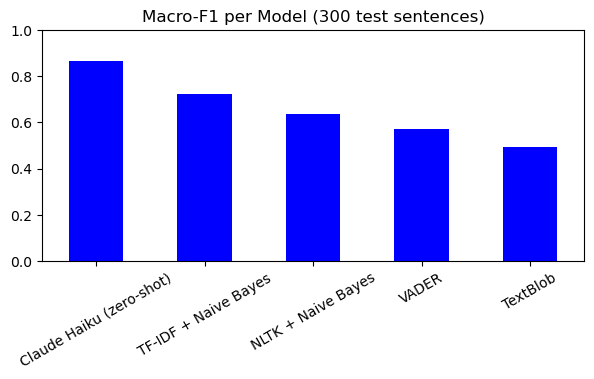

In [97]:
summary[['macro_f1']].plot.bar(figsize=(7,3), rot=30, color=['blue'], legend=False)
plt.title("Macro-F1 per Model (300 test sentences)")
plt.ylim(0,1)
plt.savefig("results/chart_macro_f1.png", bbox_inches="tight")
plt.show()

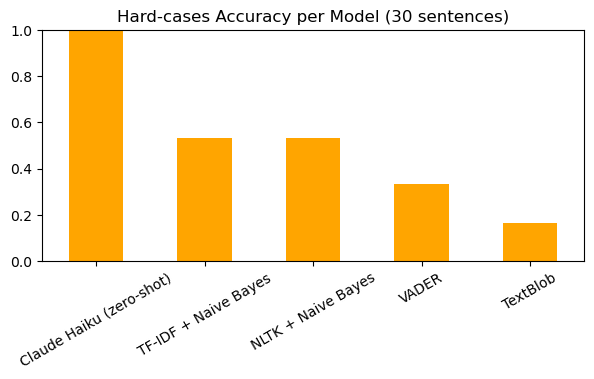

In [98]:
summary[['hard_cases_acc']].plot.bar(figsize=(7,3), rot=30, color=['orange'], legend=False)
plt.title("Hard-cases Accuracy per Model (30 sentences)")
plt.ylim(0,1)
plt.savefig("results/chart_hard_cases.png", bbox_inches="tight")
plt.show()

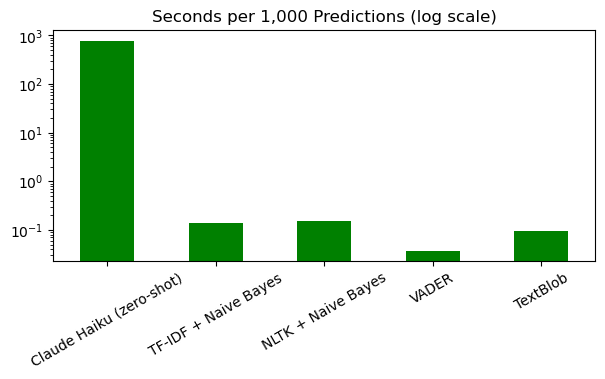

In [99]:
summary[['sec_per_1k']].plot.bar(figsize=(7,3), rot=30, color=['green'], legend=False, logy=True)
plt.title("Seconds per 1,000 Predictions (log scale)")
plt.savefig("results/chart_speed.png", bbox_inches="tight")
plt.show()

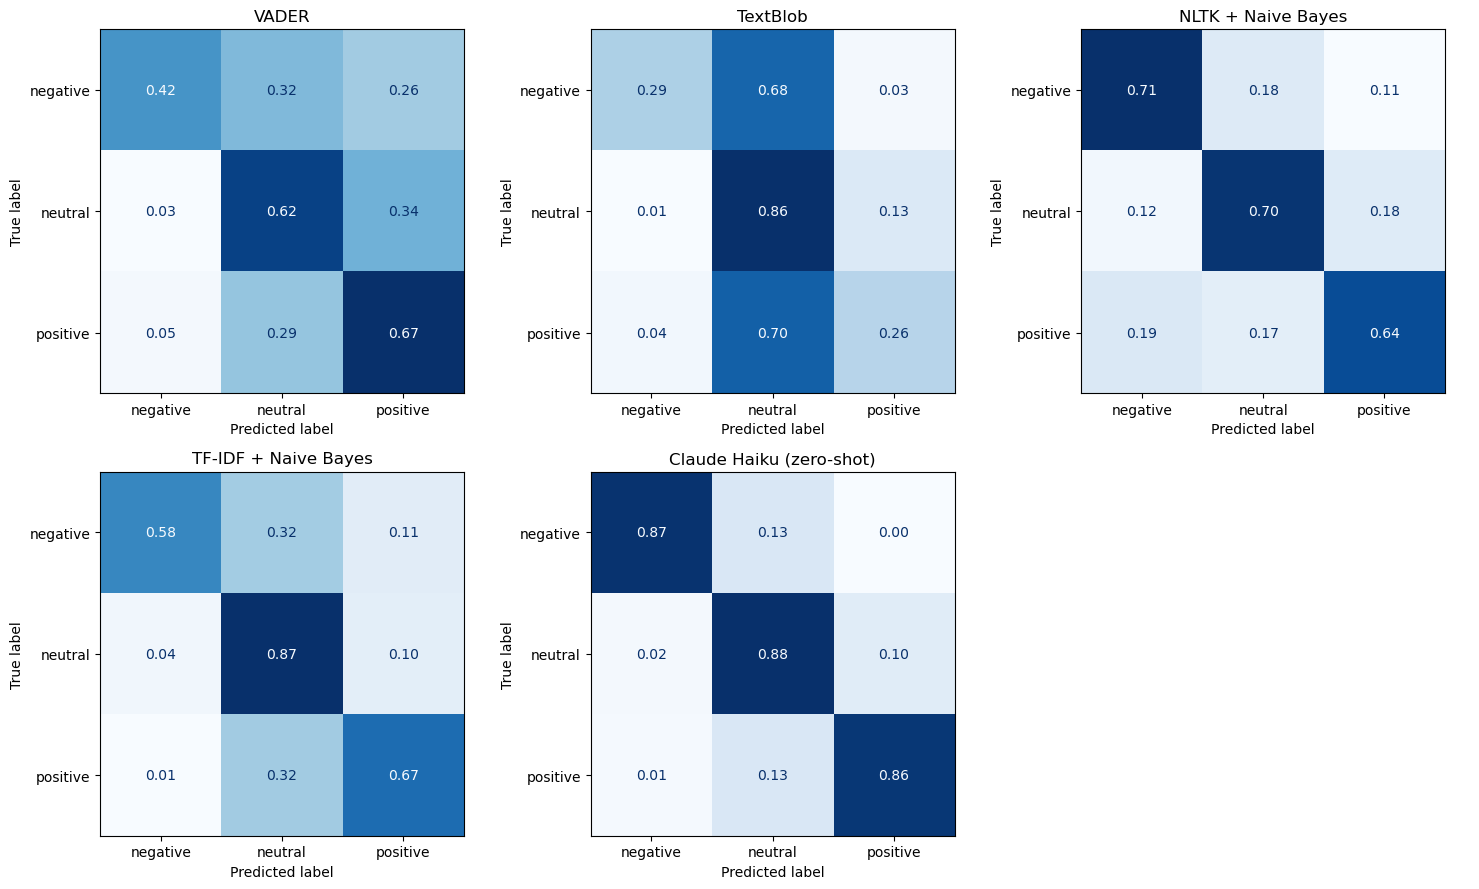

In [100]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, y_pred) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_test, y_pred, labels=LABELS, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".2f")
    ax.set_title(name)
for ax in axes.ravel()[len(preds):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("results/confusion_matrices.png")
plt.show()

## Error Analysis

In [101]:
errors = test[['text', "sentiment"]].copy()
for name, y_pred in preds.items():
    errors[name] = y_pred

errors['n_wrong'] = sum((errors[name] != errors['sentiment']).astype(int) for name in preds)

pd.set_option("display.max_colwidth", 70)
errors.head(15)

,text,sentiment,VADER,TextBlob,NLTK + Naive Bayes,TF-IDF + Naive Bayes,Claude Haiku (zero-shot),n_wrong
2729,A merger between UPM and Finnish-Swedish Stora Enso is not likely ...,neutral,neutral,neutral,negative,neutral,neutral,1
3213,The contract is for next year .,neutral,neutral,neutral,positive,positive,neutral,2
3013,"Luna took fifth place on six-under 207 , a shot behind Spain 's Be...",neutral,positive,negative,negative,neutral,neutral,3
3299,The order is related to renewing the network of the telecommunicat...,neutral,neutral,neutral,neutral,neutral,neutral,0
2914,"Furthermore , Novator Finland Oy has entered into a securities len...",positive,positive,neutral,neutral,neutral,neutral,4
4433,"Agricultural newspaper Maaseudun Tulevaisuus had 318,000 readers ,...",negative,neutral,neutral,negative,neutral,negative,3
673,Cramo slipped to a pretax loss of EUR 6.7 million from a pretax pr...,negative,neutral,neutral,negative,negative,negative,2
3357,The size of a cider bottle will remain unchanged .,neutral,neutral,neutral,neutral,neutral,neutral,0
1567,"One of the installed elevators will be a double-deck elevator , wh...",positive,positive,positive,positive,neutral,neutral,2
480,Calls to the switchboard and directory services have decreased sig...,neutral,neutral,neutral,neutral,neutral,positive,1


In [102]:
errors['n_wrong'].value_counts().sort_index()

n_wrong
0    74
1    91
2    82
3    37
4    14
5     2
Name: count, dtype: int64

### Sentences every model got wrong

In [103]:
errors[errors['n_wrong'] == len(preds)]

,text,sentiment,VADER,TextBlob,NLTK + Naive Bayes,TF-IDF + Naive Bayes,Claude Haiku (zero-shot),n_wrong
2145,Metso will supply the equipment for two process lines at Northland...,positive,negative,neutral,neutral,neutral,neutral,5
2006,"Elcoteq 's stock of orders has stabilised in the past weeks , Mr K...",positive,neutral,negative,negative,neutral,neutral,5


### Most common mistakes per model (true -> predicted)

In [104]:
for name in preds:
    wrong = errors[errors[name] != errors['sentiment']]
    print(f"==={name}=== {len(wrong)} errors")
    print((wrong['sentiment'] + " -> " + wrong[name]).value_counts().head(3).to_string())
    print()

===VADER=== 117 errors
neutral -> positive    61
positive -> neutral    24
negative -> neutral    12

===TextBlob=== 114 errors
positive -> neutral    59
negative -> neutral    26
neutral -> positive    23

===NLTK + Naive Bayes=== 95 errors
neutral -> positive     32
neutral -> negative     22
positive -> negative    16

===TF-IDF + Naive Bayes=== 68 errors
positive -> neutral    27
neutral -> positive    17
negative -> neutral    12

===Claude Haiku (zero-shot)=== 38 errors
neutral -> positive    18
positive -> neutral    11
negative -> neutral     5



### Hard cases side by side

In [105]:
hard_view = hard.copy()
hard_view['VADER'] = hard['text'].apply(vader_label)
hard_view['TextBlob'] = hard['text'].apply(textblob_label)
hard_view['NLTK + NB'] = [nb.classify(nltk_features(t)) for t in hard_tokens]
hard_view['TF-IDF + NB'] = tfidf_nb.predict(hard['text'])
if "Claude Haiku (zero-shot)" in preds:
    hard_view['Claude'] = claude_hard.to_numpy()

hard_view

,text,sentiment,VADER,TextBlob,NLTK + NB,TF-IDF + NB,Claude
0,The company did not report any losses this quarter.,positive,positive,neutral,neutral,neutral,positive
1,Sales were not as strong as analysts had hoped.,negative,neutral,positive,neutral,neutral,negative
2,Management does not expect the restructuring to hurt profitability.,positive,negative,neutral,neutral,neutral,positive
3,The merger is no longer expected to create value for shareholders.,negative,positive,neutral,neutral,neutral,negative
4,The operating loss narrowed to EUR 2.1 mn from EUR 9.4 mn a year e...,positive,negative,neutral,positive,positive,positive
5,Net debt decreased significantly during the period.,positive,negative,neutral,negative,negative,positive
6,"Costs increased sharply, eating into the operating margin.",negative,positive,neutral,negative,negative,negative
7,Unemployment claims fell to their lowest level in a decade.,positive,negative,neutral,negative,negative,positive
8,The company cut its full-year profit guidance.,negative,positive,neutral,negative,negative,negative
9,Impairment charges rose to EUR 45 mn.,negative,negative,positive,positive,positive,negative


In [106]:
errors.to_csv("results/test_with_predictions.csv", index=False)
hard_view.to_csv("results/hard_cases_with_predictions.csv", index=False)